# Step 5: GLM baseline

The industry-standard benchmark: a Poisson GLM for claim frequency and a Gamma GLM for capped claim severity, built on the Step 4 views (`model_features`, `severity_features`, `large_claim_loading`). Every GBM result in Step 6 is reported against these models.

## 1. Setup

- Imports
- Database connection from `.env`, the same way as in `02_eda.ipynb`

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter
from dotenv import load_dotenv
from sqlalchemy import create_engine, URL
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import KFold
# load the credential
load_dotenv(".env", override=True)
# build database connection
url = URL.create(
    "mysql+pymysql",
    username=os.environ["DB_USER"],
    password=os.environ["DB_PASSWORD"],
    host=os.environ["DB_HOST"],
    port=int(os.environ["DB_PORT"]),
    database=os.environ["DB_NAME"],
)
engine = create_engine(url)

## 2. Load the Step 4 views

- `model_features`: one row per policy, with the train/test split
- `severity_features`: one row per policy with claims, target `avg_claim_capped`, weight `n_claims`
- `large_claim_loading`: one row, keep `loading_per_claim` for the pure premium
- Check: 678,013 policies, 24,944 severity rows, loading about 654 per claim

In [2]:
features = pd.read_sql("SELECT * FROM model_features", engine)
sev = pd.read_sql("SELECT * FROM severity_features", engine)
lcl = pd.read_sql("SELECT * FROM large_claim_loading", engine)
features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 14 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id_pol              678013 non-null  int64  
 1   exposure            678013 non-null  float64
 2   claim_nb            678013 non-null  int64  
 3   claim_amount_total  678013 non-null  float64
 4   area                678013 non-null  object 
 5   veh_gas             678013 non-null  object 
 6   veh_brand           678013 non-null  object 
 7   region              678013 non-null  object 
 8   veh_power           678013 non-null  int64  
 9   veh_age             678013 non-null  int64  
 10  driv_age            678013 non-null  int64  
 11  bonus_malus         678013 non-null  int64  
 12  log_density         678013 non-null  float64
 13  split               678013 non-null  object 
dtypes: float64(3), int64(6), object(5)
memory usage: 72.4+ MB


In [3]:
sev.info()
lcl.info()
lcl.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24944 entries, 0 to 24943
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pol              24944 non-null  int64  
 1   exposure            24944 non-null  float64
 2   claim_nb            24944 non-null  int64  
 3   claim_amount_total  24944 non-null  float64
 4   area                24944 non-null  object 
 5   veh_gas             24944 non-null  object 
 6   veh_brand           24944 non-null  object 
 7   region              24944 non-null  object 
 8   veh_power           24944 non-null  int64  
 9   veh_age             24944 non-null  int64  
 10  driv_age            24944 non-null  int64  
 11  bonus_malus         24944 non-null  int64  
 12  log_density         24944 non-null  float64
 13  split               24944 non-null  object 
 14  n_claims            24944 non-null  int64  
 15  avg_claim_capped    24944 non-null  float64
dtypes: f

,cap,excess_cost,train_claims,loading_per_claim
0,34062.25,13904116.92,21256.0,654.12669


## 3. Bands and train/test split

- GLM bands for driver age, BonusMalus, vehicle age and vehicle power
- Regions and brands with under 1% of train exposure are grouped into "Other" (decided on train only)
- The same bands are used for frequency and severity
- Split into train and test using the `split` column; the test set is not touched until Section 8
- Each factor's reference level is the band with the most train exposure

In [4]:
# band edges are right-inclusive: (17, 20] = 18-20
AGE_EDGES = [17, 20, 25, 30, 40, 50, 65, 90]
AGE_LABELS = ["18-20", "21-25", "26-30", "31-40", "41-50", "51-65", "66+"]
BM_EDGES = [49, 50, 60, 75, 100, 150]        # 126+ is too thin on its own, so 101+ is one band
BM_LABELS = ["50", "51-60", "61-75", "76-100", "101+"]
VEH_AGE_EDGES = [-1, 0, 4, 10, 20]           # veh_age is already capped at 20 in SQL
VEH_AGE_LABELS = ["0", "1-4", "5-10", "11-20"]
POWER_EDGES = [3, 4, 5, 6, 7, 8, 10, 15]     # 11+ merged: each level above 10 has under 9k exposure years
POWER_LABELS = ["4", "5", "6", "7", "8", "9-10", "11+"]

# regions and brands under 1% of train exposure go into "Other" (decided on train only)
MIN_SHARE = 0.01
train_pol = features[features["split"] == "train"]

# to return the region and brand that contain less than 1% exposire
def thin_levels(col):
    share = train_pol.groupby(col)["exposure"].sum() / train_pol["exposure"].sum()
    return share[share < MIN_SHARE].index.tolist()

thin = {col: thin_levels(col) for col in ["region", "veh_brand"]}
print(thin)

# define a function to add new feature - bands for drive age, bonus malus
# vehicle age, and vehicle power 
def add_bands(df):
    df = df.copy()
    df["driv_age_band"] = pd.cut(df["driv_age"], AGE_EDGES, labels=AGE_LABELS)
    df["bm_band"] = pd.cut(df["bonus_malus"], BM_EDGES, labels=BM_LABELS)
    df["veh_age_band"] = pd.cut(df["veh_age"], VEH_AGE_EDGES, labels=VEH_AGE_LABELS)
    df["veh_power_band"] = pd.cut(df["veh_power"], POWER_EDGES, labels=POWER_LABELS)
    for col, levels in thin.items():
        df[col + "_grp"] = df[col].where(~df[col].isin(levels), "Other")
    return df

# same bands for frequency and severity
features = add_bands(features)
sev = add_bands(sev)

BAND_COLS = ["driv_age_band", "bm_band", "veh_age_band", "veh_power_band",
             "region_grp", "veh_brand_grp"]
assert features[BAND_COLS].notna().all().all(), "a value fell outside the band edges"

# split the data
freq_train = features[features["split"] == "train"]
freq_test = features[features["split"] == "test"]
sev_train = sev[sev["split"] == "train"]
sev_test = sev[sev["split"] == "test"]
print(f"freq_train: {len(freq_train)}, freq_test: {len(freq_test)}, "
      f"sev_train: {len(sev_train)}, sev_test: {len(sev_test)}")


# reference level = band with the most train exposure, so relativities are measured against a stable base
REF = {col: freq_train.groupby(col, observed=True)["exposure"].sum().idxmax() for col in BAND_COLS}
REF

{'region': ['R21', 'R23', 'R42', 'R43', 'R74', 'R83', 'R94'], 'veh_brand': ['B14']}
freq_train: 542144, freq_test: 135869, sev_train: 20068, sev_test: 4876


{'driv_age_band': '51-65',
 'bm_band': '50',
 'veh_age_band': '5-10',
 'veh_power_band': '6',
 'region_grp': 'R24',
 'veh_brand_grp': 'B1'}

In [5]:
# check every band on train: enough exposure and claims, and frequency moves the way the EDA showed
for col in BAND_COLS:
    g = freq_train.groupby(col, observed=True).agg(exposure=("exposure", "sum"), claims=("claim_nb", "sum"))
    g["frequency"] = g["claims"] / g["exposure"]
    g["sev_claims"] = sev_train.groupby(col, observed=True)["n_claims"].sum()
    display(g.round(4))

,exposure,claims,frequency,sev_claims
driv_age_band,,,,
18-20,2056.4044,485,0.2358,485
21-25,10861.0692,1455,0.1340,1454
26-30,23307.0059,1898,0.0814,1898
31-40,67012.8983,4645,0.0693,4645
41-50,70515.1833,5336,0.0757,5336
51-65,77457.5036,5302,0.0685,5333
66+,35478.2180,2135,0.0602,2136


,exposure,claims,frequency,sev_claims
bm_band,,,,
50,180131.2357,9316,0.0517,9348
51-60,38355.3865,2865,0.0747,2865
61-75,29571.8999,3460,0.1170,3460
76-100,35782.1357,4619,0.1291,4618
101+,2847.6249,996,0.3498,996


,exposure,claims,frequency,sev_claims
veh_age_band,,,,
0,13360.1550,958,0.0717,958
1-4,89760.8258,6641,0.0740,6640
5-10,96944.9883,7789,0.0803,7790
11-20,86622.3136,5868,0.0677,5899


,exposure,claims,frequency,sev_claims
veh_power_band,,,,
4,47999.9801,3195,0.0666,3226
5,54595.8753,4070,0.0745,4070
6,66073.6403,5126,0.0776,5126
7,62202.3232,4492,0.0722,4493
8,18143.1462,1331,0.0734,1330
9-10,24578.5572,1933,0.0786,1933
11+,13094.7604,1109,0.0847,1109


,exposure,claims,frequency,sev_claims
region_grp,,,,
Other,10063.4988,708,0.0704,708
R11,24140.9155,2070,0.0857,2069
R22,2874.1554,256,0.0891,256
R24,82051.5845,5174,0.0631,5174
R25,5318.4285,370,0.0696,370
R26,4043.5532,282,0.0697,282
R31,9241.9872,774,0.0837,774
R41,6452.9907,385,0.0597,385
R52,17499.6197,1246,0.0712,1246


,exposure,claims,frequency,sev_claims
veh_brand_grp,,,,
B1,76332.4502,5506,0.0721,5537
B10,7602.3565,618,0.0813,618
B11,5509.2551,542,0.0984,542
B12,51856.9606,3403,0.0656,3403
B13,5412.4456,422,0.0780,422
B2,75794.5863,5510,0.0727,5510
B3,22876.4614,1944,0.0850,1944
B4,10965.3068,871,0.0794,871
B5,15946.8515,1303,0.0817,1303


## 4. Frequency GLM

For each policy:

$$\text{claims} \sim \text{Poisson}(\mu), \qquad \mu = \text{expected claims} = \text{rate} \times \text{exposure}$$

$$\log(\mu) = \underbrace{1 \times \log(\text{exposure})}_{\text{known, not estimated}} + \underbrace{\alpha_0 + \sum_i \alpha_i x_i}_{\text{estimated}}$$

- $\alpha_0$ is the intercept: the log rate for a policy in the reference band of every factor
- for a banded factor, $x_i$ is a 0/1 dummy for one band, so $e^{\alpha_i}$ is that band's relativity against the reference band
- for a numeric feature (`log_density`), $x_i$ is the value itself, so $e^{\alpha_i}$ is the change in rate for each 1-unit increase
- predicted frequency = $\mu \div \text{exposure} = e^{\alpha_0} \times \prod_i e^{\alpha_i x_i}$

Notes:

- Poisson, log link, target `claim_nb`, `log(exposure)` as an offset
- Use only one of `area` and `log_density` (they carry the same information)
- The EDA found overdispersion (Cameron–Trivedi α = 0.125), so use standard errors scaled for it (quasi-Poisson)

In [6]:

# veh_gas is a two-level text factor, so it also needs a reference level
REF["veh_gas"] = freq_train.groupby("veh_gas")["exposure"].sum().idxmax()
FACTORS = BAND_COLS + ["veh_gas"]

# C(col, Treatment('ref')) = one 0/1 dummy per level, with the reference level left out
def cat(col):
    return f"C({col}, Treatment('{REF[col]}'))"

# log_density rather than area: same information, one coefficient
freq_formula = "claim_nb ~ " + " + ".join(cat(c) for c in FACTORS) + " + log_density"
print(freq_formula)

# Poisson, log link, log(exposure) as the offset (coefficient fixed at 1)
# scale="X2": standard errors scaled by the Pearson dispersion (quasi-Poisson)
freq_glm = smf.glm(
    freq_formula,
    data=freq_train,
    family=sm.families.Poisson(),
    offset=np.log(freq_train["exposure"]),
).fit(scale="X2")
print(freq_glm.summary())


claim_nb ~ C(driv_age_band, Treatment('51-65')) + C(bm_band, Treatment('50')) + C(veh_age_band, Treatment('5-10')) + C(veh_power_band, Treatment('6')) + C(region_grp, Treatment('R24')) + C(veh_brand_grp, Treatment('B1')) + C(veh_gas, Treatment('Regular')) + log_density
                 Generalized Linear Model Regression Results                  
Dep. Variable:               claim_nb   No. Observations:               542144
Model:                            GLM   Df Residuals:                   542097
Model Family:                 Poisson   Df Model:                           46
Link Function:                    Log   Scale:                          1.6889
Method:                          IRLS   Log-Likelihood:                -50884.
Date:                Wed, 04 Nov 2026   Deviance:                   1.3103e+05
Time:                        01:32:35   Pearson chi2:                 9.16e+05
No. Iterations:                     9   Pseudo R-squ. (CS):           0.007143
Covariance Type:   

In [7]:
# dispersion: the EDA found a Pearson ratio of about 1.70
print(f"dispersion (Pearson): {freq_glm.scale:.3f}")

# with an intercept and log link, predicted claims add up to actual claims on train
print(f"actual claims: {freq_train['claim_nb'].sum()}, predicted: {freq_glm.fittedvalues.sum():.1f}")

# base rate = predicted frequency for a policy in every reference level, at log_density = 0
print(f"base rate exp(intercept): {np.exp(freq_glm.params['Intercept']):.4f}")


dispersion (Pearson): 1.689
actual claims: 21256, predicted: 21256.0
base rate exp(intercept): 0.0341


## 5. Severity GLM

- Gamma, log link, target `avg_claim_capped`, weight `n_claims`
- Train policies with claims only

In [8]:
# a Gamma GLM needs every target above 0
assert (sev_train["avg_claim_capped"] > 0).all()

# same factors and reference levels as frequency, so the two relativity tables line up
sev_formula = "avg_claim_capped ~ " + " + ".join(cat(c) for c in FACTORS) + " + log_density"

# Gamma, log link, no offset: claim size does not depend on how long the policy ran
# var_weights: the target is an average over n_claims claims, so its variance shrinks as 1/n_claims
sev_glm = smf.glm(
    sev_formula,
    data=sev_train,
    family=sm.families.Gamma(link=sm.families.links.Log()),
    var_weights=sev_train["n_claims"],
).fit(scale="X2")
print(sev_glm.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:       avg_claim_capped   No. Observations:                20068
Model:                            GLM   Df Residuals:                    20021
Model Family:                   Gamma   Df Model:                           46
Link Function:                    Log   Scale:                          3.4324
Method:                          IRLS   Log-Likelihood:            -1.7611e+05
Date:                Wed, 04 Nov 2026   Deviance:                       23439.
Time:                        01:32:36   Pearson chi2:                 6.87e+04
No. Iterations:                    16   Pseudo R-squ. (CS):           0.005699
Covariance Type:            nonrobust                                         
                                                    coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------

In [9]:
print(f"dispersion (Pearson): {sev_glm.scale:.3f}")

# Gamma with a log link does not balance exactly like Poisson does; this gap is part of what k corrects
actual_cost = (sev_train["avg_claim_capped"] * sev_train["n_claims"]).sum()
pred_cost = (sev_glm.fittedvalues * sev_train["n_claims"]).sum()
print(f"actual capped cost: {actual_cost:,.0f}, predicted: {pred_cost:,.0f}, ratio: {actual_cost / pred_cost:.4f}")

print(f"base severity exp(intercept): {np.exp(sev_glm.params['Intercept']):,.0f}")


dispersion (Pearson): 3.432
actual capped cost: 35,997,617, predicted: 36,002,496, ratio: 0.9999
base severity exp(intercept): 1,666


In [10]:
from scipy import stats

def fit_sev(factors, numeric):
    formula = "avg_claim_capped ~ " + " + ".join([cat(c) for c in factors] + numeric)
    return smf.glm(formula, data=sev_train,
                   family=sm.families.Gamma(link=sm.families.links.Log()),
                   var_weights=sev_train["n_claims"]).fit(scale="X2")

# drop one factor at a time; F-test on the deviance increase, scaled by the dispersion
rows = []
for col in FACTORS + ["log_density"]:
    if col == "log_density":
        reduced = fit_sev(FACTORS, [])
    else:
        reduced = fit_sev([c for c in FACTORS if c != col], ["log_density"])
    df_diff = reduced.df_resid - sev_glm.df_resid
    F = (reduced.deviance - sev_glm.deviance) / df_diff / sev_glm.scale
    rows.append({"factor": col, "df": df_diff, "F": F, "p": stats.f.sf(F, df_diff, sev_glm.df_resid)})
pd.DataFrame(rows).sort_values("p").round(4)


,factor,df,F,p
4,region_grp,15,2.8479,0.0002
0,driv_age_band,6,3.9433,0.0006
2,veh_age_band,3,4.1219,0.0062
1,bm_band,4,2.6872,0.0296
3,veh_power_band,6,1.4415,0.1943
5,veh_brand_grp,10,1.1005,0.3572
7,log_density,1,0.8234,0.3642
6,veh_gas,1,0.0084,0.9268


In [11]:
# severity keeps only the factors that passed the group test
SEV_FACTORS = ["driv_age_band", "bm_band", "veh_age_band", "region_grp"]
sev_reduced = fit_sev(SEV_FACTORS, [])

# joint F-test: does dropping power, brand, density and fuel together make the fit worse?
df_diff = sev_reduced.df_resid - sev_glm.df_resid
F = (sev_reduced.deviance - sev_glm.deviance) / df_diff / sev_glm.scale
print(f"df: {df_diff}, F: {F:.3f}, p: {stats.f.sf(F, df_diff, sev_glm.df_resid):.4f}")


df: 18, F: 1.327, p: 0.1591


In [12]:
# the four dropped factors add nothing jointly (F = 1.33 on 18 df, p = 0.16), so severity uses the reduced model
sev_full = sev_glm
sev_glm = sev_reduced
print(sev_glm.summary())

print(f"dispersion (Pearson): {sev_glm.scale:.3f}")
actual_cost = (sev_train["avg_claim_capped"] * sev_train["n_claims"]).sum()
pred_cost = (sev_glm.fittedvalues * sev_train["n_claims"]).sum()
print(f"actual capped cost: {actual_cost:,.0f}, predicted: {pred_cost:,.0f}, ratio: {actual_cost / pred_cost:.4f}")
print(f"base severity exp(intercept): {np.exp(sev_glm.params['Intercept']):,.0f}")


                 Generalized Linear Model Regression Results                  
Dep. Variable:       avg_claim_capped   No. Observations:                20068
Model:                            GLM   Df Residuals:                    20039
Model Family:                   Gamma   Df Model:                           28
Link Function:                    Log   Scale:                          3.4773
Method:                          IRLS   Log-Likelihood:            -1.7625e+05
Date:                Wed, 04 Nov 2026   Deviance:                       23521.
Time:                        01:32:42   Pearson chi2:                 6.97e+04
No. Iterations:                    13   Pseudo R-squ. (CS):           0.004457
Covariance Type:            nonrobust                                         
                                                    coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------

## 6. Relativities and sanity checks

- Relativity table for each model: `exp(coef)`, with confidence intervals
- Sanity check: high BonusMalus bands above 1 and rising. Young drivers' age relativity can be below 1 because they start at BonusMalus 100; their overall predicted frequency must still be well above the 51-65 base
- Save the tables for the README

In [13]:
import re

# "C(driv_age_band, Treatment('51-65'))[T.18-20]" -> factor "driv_age_band", level "18-20"
PARAM_RE = re.compile(r"C\((\w+), Treatment\('.+?'\)\)\[T\.(.+)\]")
FACTOR_RANK = {f: i for i, f in enumerate(FACTORS + ["log_density"])}

# bands keep their pd.cut order (18-20 before 21-25); text factors sort alphabetically
def level_order(factor, level):
    if factor not in REF:
        return 0
    col = freq_train[factor]
    levels = list(col.cat.categories) if hasattr(col, "cat") else sorted(col.unique())
    return levels.index(level)

def relativity_table(model):
    ci = np.exp(model.conf_int())
    rows = []
    for name in model.params.index.drop("Intercept"):
        m = PARAM_RE.fullmatch(name)
        factor, level = (m.group(1), m.group(2)) if m else (name, "per unit")   # numeric terms, e.g. log_density
        rows.append({"factor": factor, "level": level,
                     "relativity": np.exp(model.params[name]),
                     "ci_low": ci.loc[name, 0], "ci_high": ci.loc[name, 1],
                     "p": model.pvalues[name]})
    # the reference level has no coefficient: its relativity is 1 by definition
    for factor in {r["factor"] for r in rows} & REF.keys():
        rows.append({"factor": factor, "level": REF[factor], "relativity": 1.0,
                     "ci_low": np.nan, "ci_high": np.nan, "p": np.nan})
    table = pd.DataFrame(rows)
    table["factor_rank"] = table["factor"].map(FACTOR_RANK)
    table["level_rank"] = [level_order(f, l) for f, l in zip(table["factor"], table["level"])]
    return (table.sort_values(["factor_rank", "level_rank"])
                 .drop(columns=["factor_rank", "level_rank"])
                 .reset_index(drop=True))

freq_rel = relativity_table(freq_glm)
sev_rel = relativity_table(sev_glm)
display(freq_rel.round(3))
display(sev_rel.round(3))

,factor,level,relativity,ci_low,ci_high,p
0,driv_age_band,18-20,1.426,1.254,1.622,0.000
1,driv_age_band,21-25,0.788,0.724,0.857,0.000
2,driv_age_band,26-30,0.585,0.543,0.630,0.000
3,driv_age_band,31-40,0.717,0.680,0.757,0.000
4,driv_age_band,41-50,1.035,0.985,1.088,0.173
5,driv_age_band,51-65,1.000,NaN,NaN,NaN
6,driv_age_band,66+,0.978,0.915,1.044,0.502
7,bm_band,50,1.000,NaN,NaN,NaN
8,bm_band,51-60,1.616,1.527,1.711,0.000
9,bm_band,61-75,2.590,2.453,2.735,0.000


,factor,level,relativity,ci_low,ci_high,p
0,driv_age_band,18-20,1.410,1.173,1.694,0.000
1,driv_age_band,21-25,1.012,0.895,1.145,0.845
2,driv_age_band,26-30,0.951,0.856,1.058,0.356
3,driv_age_band,31-40,1.008,0.934,1.088,0.845
4,driv_age_band,41-50,1.012,0.943,1.087,0.739
5,driv_age_band,51-65,1.000,NaN,NaN,NaN
6,driv_age_band,66+,1.115,1.015,1.224,0.023
7,bm_band,50,1.000,NaN,NaN,NaN
8,bm_band,51-60,1.067,0.984,1.156,0.115
9,bm_band,61-75,1.037,0.961,1.119,0.346


In [14]:
def rel(table, factor):
    return table[table["factor"] == factor].set_index("level")["relativity"]

# BonusMalus: every band above 50 should be above 1, rising with the score
bm = rel(freq_rel, "bm_band")
print("BonusMalus frequency relativities:", bm.round(3).to_dict())
print("all above 1:", (bm.drop(REF["bm_band"]) > 1).all(), "| rising:", bm.is_monotonic_increasing)

# young drivers: their own age relativity can be below 1, because they start at BonusMalus 100
# and the BM loading already charges for part of their risk. The combined price is what must be high.
check = freq_train.assign(pred=freq_glm.fittedvalues).groupby("driv_age_band", observed=True).agg(
    exposure=("exposure", "sum"), claims=("claim_nb", "sum"),
    pred_claims=("pred", "sum"), mean_bm=("bonus_malus", "mean"))
check["age_relativity"] = rel(freq_rel, "driv_age_band").reindex(check.index.astype(str)).values
check["predicted_freq"] = check["pred_claims"] / check["exposure"]
check["actual_freq"] = check["claims"] / check["exposure"]
display(check[["age_relativity", "mean_bm", "predicted_freq", "actual_freq"]].round(4))

BonusMalus frequency relativities: {'50': 1.0, '51-60': 1.616, '61-75': 2.59, '76-100': 2.884, '101+': 7.553}
all above 1: True | rising: True


,age_relativity,mean_bm,predicted_freq,actual_freq
driv_age_band,,,,
18-20,1.4264,95.2336,0.2358,0.2358
21-25,0.7877,87.5939,0.1340,0.1340
26-30,0.5848,73.8625,0.0814,0.0814
31-40,0.7173,61.2083,0.0693,0.0693
41-50,1.0351,55.0698,0.0757,0.0757
51-65,1.0000,53.6214,0.0685,0.0685
66+,0.9777,52.5217,0.0602,0.0602


In [15]:
# saved next to the models, so the README and the Step 7 GLM-vs-GBM comparison can read them
os.makedirs("models", exist_ok=True)
freq_rel.to_csv("models/glm_freq_relativities.csv", index=False)
sev_rel.to_csv("models/glm_sev_relativities.csv", index=False)

## 7. Balance factor k

- 5-fold cross-validation on train only: refit both GLMs on 4 folds, predict the 5th
- k = actual capped cost ÷ predicted capped cost (frequency × severity × exposure), on the out-of-fold predictions
- Expect k close to 1 for the GLM. Record it either way

In [16]:
# severity uses the reduced factor set chosen in Section 5
SEV_FORMULA = "avg_claim_capped ~ " + " + ".join(cat(c) for c in SEV_FACTORS)

def fit_freq_glm(data):
    return smf.glm(freq_formula, data=data, family=sm.families.Poisson(),
                   offset=np.log(data["exposure"])).fit(scale="X2")

def fit_sev_glm(data):
    return smf.glm(SEV_FORMULA, data=data, family=sm.families.Gamma(link=sm.families.links.Log()),
                   var_weights=data["n_claims"]).fit(scale="X2")

# predicted claims per policy-year: offset 0 = log(1 year of exposure)
def predict_rate(model, data):
    return model.predict(data, offset=np.zeros(len(data)))

# actual capped claim cost per policy, 0 for policies without a claim row
def capped_cost(policies, sev_rows):
    cost = (sev_rows["avg_claim_capped"] * sev_rows["n_claims"]).set_axis(sev_rows["id_pol"])
    return policies["id_pol"].map(cost).fillna(0).to_numpy()

actual_train = capped_cost(freq_train, sev_train)
oof_pred = np.zeros(len(freq_train))
fold_k = []

# 5-fold CV on train: each fold is predicted by models that never saw it
kf = KFold(n_splits=5, shuffle=True, random_state=42)
for fit_idx, val_idx in kf.split(freq_train):
    fit_pol, val_pol = freq_train.iloc[fit_idx], freq_train.iloc[val_idx]
    # a policy's severity row goes in the same fold as its frequency row
    sev_fit_rows = sev_train[sev_train["id_pol"].isin(fit_pol["id_pol"])]
    f_model, s_model = fit_freq_glm(fit_pol), fit_sev_glm(sev_fit_rows)
    # predicted capped cost = claims per year x exposure x cost per claim
    oof_pred[val_idx] = (predict_rate(f_model, val_pol) * val_pol["exposure"] * s_model.predict(val_pol)).to_numpy()
    fold_k.append(actual_train[val_idx].sum() / oof_pred[val_idx].sum())

k = actual_train.sum() / oof_pred.sum()
print("k per fold:", np.round(fold_k, 4))
print(f"k = {k:.4f}")

k per fold: [1.0863 0.943  0.9811 1.0056 0.9912]
k = 1.0010


## 8. Test-set metrics

Write these as functions, so the Step 6 GBM notebook can reuse them:

- Frequency: mean Poisson deviance on `claim_nb / exposure`, weighted by exposure
- Severity: mean Gamma deviance, weighted by claim count
- Pure premium: Gini from an exposure-weighted Lorenz curve, on capped cost (one 4M claim would otherwise dominate the ranking)
- Calibration: actual ÷ predicted capped cost, before and after k (above 1 = underpriced)

Pure premium per policy-year = frequency × (k × severity + loading per claim).

In [ ]:
from sklearn.metrics import mean_poisson_deviance, mean_gamma_deviance

# metric functions: plain arrays in, one number out, so the GBM notebook can reuse them as they are
# measure the goodness of fit or prediction error with accounting for the variance 
# structure of poisson like data
def freq_deviance(claims, exposure, pred_rate):
    # Poisson deviance of claims per year, weighted by exposure
    return mean_poisson_deviance(claims / exposure, pred_rate, sample_weight=exposure)

def sev_deviance(avg_claim, n_claims, pred_sev):
    # Gamma deviance of the average claim, weighted by the number of claims it averages
    return mean_gamma_deviance(avg_claim, pred_sev, sample_weight=n_claims)

def gini(actual_cost, pred_pp, exposure):
    # Lorenz curve: policies from lowest to highest predicted pure premium,
    # cumulative share of exposure (x) against cumulative share of actual cost (y)
    actual_cost, pred_pp, exposure = map(np.asarray, (actual_cost, pred_pp, exposure))
    order = np.argsort(pred_pp, kind="stable")
    x = np.concatenate([[0], np.cumsum(exposure[order])]) / exposure.sum()
    y = np.concatenate([[0], np.cumsum(actual_cost[order])]) / actual_cost.sum()
    area = np.sum(np.diff(x) * (y[1:] + y[:-1]) / 2)
    return 1 - 2 * area   # 0 = no better than random, higher = better ranking

loading = lcl.loc[0, "loading_per_claim"]

# test-set predictions, one row per policy
test = freq_test[["id_pol", "exposure", "claim_nb"]].copy()
test["pred_freq"] = predict_rate(freq_glm, freq_test)
test["pred_sev"] = sev_glm.predict(freq_test)
test["actual_capped"] = capped_cost(freq_test, sev_test)
test["pred_capped_pp"] = test["pred_freq"] * k * test["pred_sev"]            # per policy-year, after k
test["pure_premium"] = test["pred_freq"] * (k * test["pred_sev"] + loading)   # adds the large-claim loading

pred_cost = (test["pred_freq"] * test["exposure"] * test["pred_sev"]).sum()
metrics = {
    "freq_deviance": freq_deviance(test["claim_nb"], test["exposure"], test["pred_freq"]),
    "sev_deviance": sev_deviance(sev_test["avg_claim_capped"], sev_test["n_claims"], sev_glm.predict(sev_test)),
    "gini": gini(test["actual_capped"], test["pred_capped_pp"], test["exposure"]),
    "k": k,
    # actual ÷ predicted, same direction as k and the decile chart: above 1 = underpriced
    "calib_before_k": test["actual_capped"].sum() / pred_cost,
    "calib_after_k": test["actual_capped"].sum() / (k * pred_cost),
}

# context for the deviance: a model that gives every policy the train average rate
null_rate = freq_train["claim_nb"].sum() / freq_train["exposure"].sum()
null_dev = freq_deviance(test["claim_nb"], test["exposure"], np.full(len(test), null_rate))
print(f"frequency deviance: GLM {metrics['freq_deviance']:.4f} vs flat rate {null_dev:.4f} "
      f"({1 - metrics['freq_deviance'] / null_dev:.1%} lower)")
pd.Series(metrics).round(4)

frequency deviance: GLM 0.4482 vs flat rate 0.4706 (4.8% lower)


freq_deviance     0.4482
sev_deviance      1.1553
gini              0.3233
k                 1.0010
calib_before_k    0.9683
calib_after_k     0.9673
dtype: float64

## 9. Decile calibration

- Sort test policies by predicted capped pure premium and cut into 10 equal-exposure groups
- Chart actual ÷ predicted for each group
- k only fixes the total, so any group that is clearly off goes in the limitations
- Save the chart to `figures/`

,exposure,actual,predicted,actual_per_year,predicted_per_year,actual_over_predicted
decile,,,,,,
1,7166.989,404966.26,363318.811,56.504,50.693,1.115
2,7166.443,444693.61,461088.281,62.052,64.340,0.964
3,7167.472,522000.08,528246.820,72.829,73.701,0.988
4,7167.324,446682.85,591027.913,62.322,82.461,0.756
5,7167.546,636021.41,654910.444,88.736,91.372,0.971
6,7167.171,705434.25,733382.917,98.426,102.325,0.962
7,7166.677,717644.65,848936.719,100.136,118.456,0.845
8,7167.007,1143022.13,1036583.559,159.484,144.633,1.103
9,7167.818,1397790.42,1355728.523,195.009,189.141,1.031


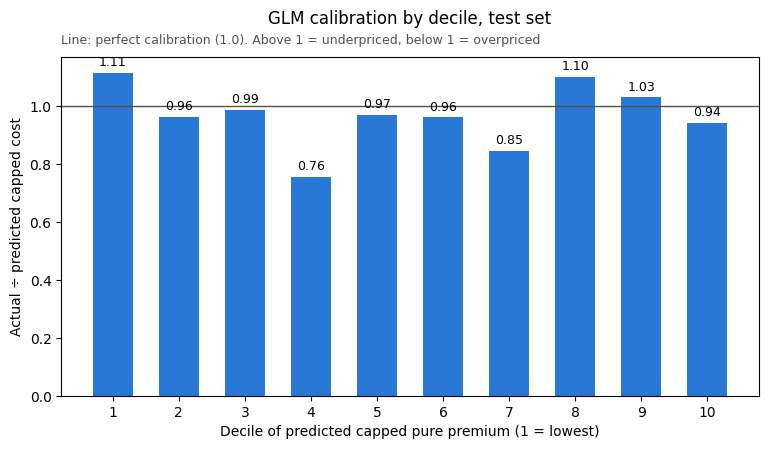

In [18]:
# same colors as 02_eda.ipynb
BLUE, INK_2 = "#2a78d6", "#52514e"

# 10 groups of equal exposure, from lowest to highest predicted capped pure premium
d = test.sort_values("pred_capped_pp")
cum_share = d["exposure"].cumsum() / d["exposure"].sum()
d["decile"] = np.ceil(cum_share * 10).clip(1, 10).astype(int)
dec = d.assign(pred_cost=d["pred_capped_pp"] * d["exposure"]).groupby("decile").agg(
    exposure=("exposure", "sum"), actual=("actual_capped", "sum"), predicted=("pred_cost", "sum"))
dec["actual_per_year"] = dec["actual"] / dec["exposure"]
dec["predicted_per_year"] = dec["predicted"] / dec["exposure"]
dec["actual_over_predicted"] = dec["actual"] / dec["predicted"]
display(dec.round(3))

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.bar(dec.index, dec["actual_over_predicted"], width=0.6, color=BLUE)
ax.axhline(1, color=INK_2, linewidth=1)
for x, v in zip(dec.index, dec["actual_over_predicted"]):
    ax.annotate(f"{v:.2f}", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)
ax.set_xticks(dec.index)
ax.set_xlabel("Decile of predicted capped pure premium (1 = lowest)")
ax.set_ylabel("Actual ÷ predicted capped cost")
ax.set_title("GLM calibration by decile, test set", pad=24)
ax.text(0, 1.04, "Line: perfect calibration (1.0). Above 1 = underpriced, below 1 = overpriced",
        transform=ax.transAxes, color=INK_2, fontsize=9)
fig.savefig("figures/glm_decile_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Results

- One results row for the GLM: frequency deviance, severity deviance, Gini, k, calibration before and after k
- Save it, so Step 6 can add the GBM row next to it

In [19]:
# one results row per model; the GBM notebook adds its row to this file
results = pd.DataFrame([{"model": "GLM", **metrics}])
results.to_csv("models/results.csv", index=False)
display(results.round(4))

# per-policy test predictions, keyed by id_pol, for the Step 7 GLM-vs-GBM comparison (double lift)
test[["id_pol", "pred_freq", "pred_sev", "pure_premium"]].to_csv("models/glm_test_predictions.csv", index=False)

# fitted models without their training data, for the Streamlit app's GLM premium
freq_glm.save("models/glm_freq.pickle", remove_data=True)
sev_glm.save("models/glm_sev.pickle", remove_data=True)

,model,freq_deviance,sev_deviance,gini,k,calib_before_k,calib_after_k
0,GLM,0.4482,1.1553,0.3233,1.001,0.9683,0.9673


**Conclusion.**

The GLM baseline is fitted and scored on the test set. Every GBM result in Step 6 is compared with these numbers.

- **Frequency:** Poisson deviance 0.4482, 4.8% below a flat rate (0.4706). BonusMalus is by far the strongest factor: policies at 101+ claim 7.55× as often as those at 50, and each band is above the one before it.
- **Young drivers:** the age relativities are below 1 from 21 to 40 (0.58 at 26-30). This is not an error: young drivers start at a high BonusMalus (average 88 to 95 at ages 18 to 25), so the BonusMalus relativity already charges for most of their risk. Predicted frequency by age band still matches actual on train.
- **Severity:** Gamma deviance 1.1553. Vehicle power, brand, fuel and density add nothing jointly (F = 1.33 on 18 df, p = 0.16), so the model keeps driver age, BonusMalus, vehicle age and region. Most relativities are between 0.85 and 1.20.
- **Ranking:** Gini 0.323. Actual capped cost per policy-year rises from 57 in the cheapest decile to 318 in the most expensive.
- **Calibration:** k = 1.001 (0.943 to 1.086 across the five folds). On test, actual ÷ predicted capped cost is 0.968 before k and 0.967 after: the model over-predicts by about 3%, within the variation between folds.
- **Limitation:** k only fixes the total. Decile 4 is over-predicted by 24% (0.76) and decile 7 by 16% (0.85), while deciles 1 and 8 are under-predicted by 10 to 12%.

Saved: `models/glm_freq_relativities.csv`, `models/glm_sev_relativities.csv`, `models/glm_test_predictions.csv`, the GLM row in `models/results.csv`, and the two fitted models as pickle files (kept out of git because of their size).